# 07 — Explainability: why a forecast says what it says

A household will not trust "€640 of groceries next month" without a reason. Two kinds of
explanation:

- **by construction**, for the statistical models: an average *is* its explanation ("the
  average of the last 6 months"); ETS is a level, a trend and a season updated month by month,
  which a decomposition shows;
- **post hoc**, for the trees: **SHAP** values (Lundberg & Lee) split each forecast into the
  contributions of its features (last month, the same month last year, the calendar month…),
  adding up exactly to the forecast minus the average prediction. For tree ensembles,
  **TreeSHAP** computes them exactly and fast; LightGBM does it natively (`pred_contrib=True`),
  which is what the app uses (F-FCT-6: "the three features that weighed most").

In [1]:
import warnings
from decimal import Decimal

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler

import study
import synthetic

warnings.filterwarnings("ignore")
v = study.bench()
v["category"] = pd.Categorical(v["category"])

fc = MLForecast(models={"lgbm": lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=7,
                                                  min_child_samples=5, deterministic=True, num_threads=1,
                                                  random_state=20261028, verbosity=-1)},
                freq="MS", lags=[1, 2, 3, 6, 12],
                lag_transforms={1: [RollingMean(window_size=3), RollingMean(window_size=6)]},
                date_features=["month"], target_transforms=[LocalStandardScaler()])
X = fc.preprocess(v[["unique_id", "ds", "y", "category"]], static_features=["category"])
features = [c for c in X.columns if c not in ("unique_id", "ds", "y")]
model = fc.models["lgbm"].fit(X[features], X["y"])
explainer = shap.TreeExplainer(model)
sample = X.sample(3000, random_state=0)
values = explainer.shap_values(sample[features])
print(f"{len(X):,} training rows, features: {features}")

23,688 training rows, features: ['category', 'lag1', 'lag2', 'lag3', 'lag6', 'lag12', 'rolling_mean_lag1_window_size3', 'rolling_mean_lag1_window_size6', 'month']


## Global importance

The mean absolute SHAP value of each feature over 3,000 training rows (scaled target: these are
in units of each series' standard deviation):

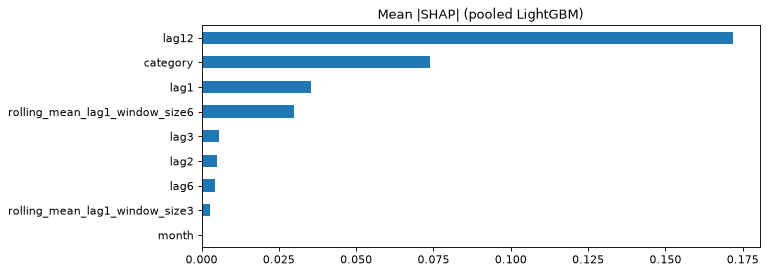

lag12                             0.172
category                          0.074
lag1                              0.035
rolling_mean_lag1_window_size6    0.030
lag3                              0.006
lag2                              0.005
lag6                              0.004
rolling_mean_lag1_window_size3    0.003
month                             0.000
dtype: float64

In [2]:
imp = pd.Series(np.abs(values).mean(axis=0), index=features).sort_values()
imp.plot.barh(title="Mean |SHAP| (pooled LightGBM)")
plt.show()
imp.sort_values(ascending=False).round(3)

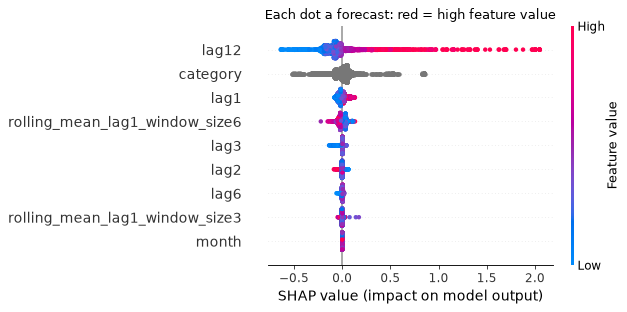

In [3]:
shap.summary_plot(values, sample[features], show=False, plot_size=(8, 4))
plt.title("Each dot a forecast: red = high feature value")
plt.tight_layout()
plt.show()

The **same month last year** (`lag12`) dominates: it carries the seasonal categories (holidays,
school, December) and, the target being scaled per series, the level too. The **category** comes
second (one model treats a gift series and a grocery series differently), then last month and the
6-month mean. The **calendar month adds nothing** (mean |SHAP| 0.000) once `lag12` is there:
the two encode the same information and the trees use the more specific one. Dropping `month`
would lose nothing on this panel.

## One forecast, explained

A leisure series in July, the holiday month: each bar is a feature pushing the forecast up or
down from the average prediction.

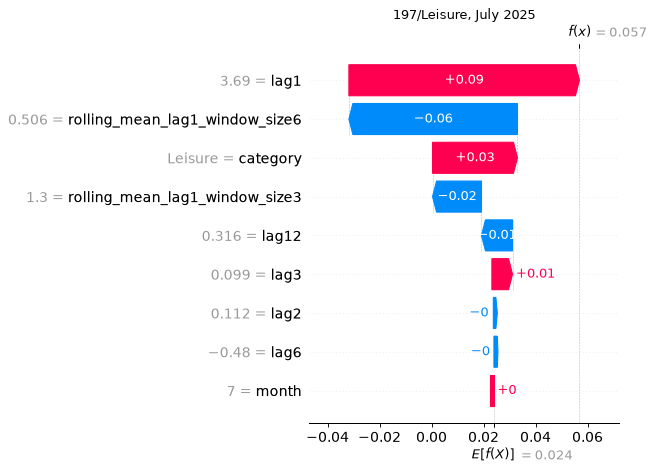

In [4]:
pick = X[(X["category"] == "Leisure") & (X["ds"].dt.month == 7)].index[-1]
row = X.loc[pick]
sv = explainer(X.loc[[pick], features])
shap.plots.waterfall(sv[0], show=False)
plt.title(f"{row['unique_id']}, {row['ds']:%B %Y}")
plt.tight_layout()
plt.show()

## What the app shows: its own engine on the demo household

`kwak_analytics.forecast.run` fits one LightGBM per household (notebook 04) and returns, for
each category, the share of the absolute TreeSHAP contributions of each feature in its next
month's forecast; the page names the top three in words. Here, on the demo's variable series:

In [5]:
from kwak_analytics.forecast import SeriesInput, run
from kwak_core.budget import Month
from kwak_core.forecast import cuts

demo = synthetic.demo_household()
months = sorted(demo["ds"].unique())
inputs = []
for cat, g in demo.groupby("category"):
    y = g.sort_values("ds")["variable"].to_numpy()
    nz = np.nonzero(y)[0]
    if len(nz) < 3:
        continue
    start = int(nz[0])
    inputs.append((cat, SeriesInput(__import__("uuid").uuid5(__import__("uuid").NAMESPACE_URL, cat),
                                    [Decimal(str(round(x, 2))) for x in y[start:]], start, len(y) - start >= 24)))
first = Month(pd.Timestamp(months[0]).year, pd.Timestamp(months[0]).month)
res = run([s for _, s in inputs], first=first, n=len(months), cuts=cuts(len(months)))
rows = []
for cat, s in inputs:
    shares = res.contributions.get(s.key, ())
    rows.append({"category": cat, **{f"#{i + 1}": f"{n} ({float(w):.0%})" for i, (n, w) in enumerate(shares[:3])}})
pd.DataFrame(rows)

,category,#1,#2,#3
0,Benefits,lag2 (40%),mean6 (16%),mean3 (12%)
1,Children,lag2 (32%),mean6 (20%),lag12 (18%)
2,Gifts,lag12 (26%),mean6 (21%),lag2 (18%)
3,Groceries,lag12 (34%),month (25%),lag6 (17%)
4,Health,lag2 (38%),mean6 (22%),lag6 (10%)
5,Home,lag1 (36%),lag2 (30%),lag12 (12%)
6,Leisure,mean6 (34%),lag1 (18%),lag12 (13%)
7,Miscellaneous,lag12 (25%),lag1 (19%),category (17%)
8,Other income,lag12 (45%),month (21%),lag1 (7%)
9,Refunds,lag2 (26%),lag12 (22%),lag6 (11%)


## ETS, explained by its components

AutoETS chooses, per series, an **error** (additive or multiplicative), a **trend** (none,
additive, damped) and a **season** (none, additive, multiplicative) by AICc. Which shapes it
picked on the benchmark series (fitted on all 48 months), by category:

In [6]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

sf = StatsForecast(models=[AutoETS(season_length=12)], freq="MS", n_jobs=-1)
sf.fit(df=v[["unique_id", "ds", "y"]])
uids = sf.uids if hasattr(sf, "uids") else v["unique_id"].unique()
methods = [m.model_["method"] for m in sf.fitted_[:, 0]]
spec = pd.DataFrame({"unique_id": list(uids), "ETS": methods})
spec["category"] = spec["unique_id"].str.split("/").str[1]
pd.crosstab(spec["category"], spec["ETS"])

ETS,"ETS(A,A,N)","ETS(A,Ad,N)","ETS(A,N,A)","ETS(A,N,N)","ETS(M,A,A)","ETS(M,A,N)","ETS(M,Ad,A)","ETS(M,Ad,N)","ETS(M,N,A)","ETS(M,N,M)","ETS(M,N,N)"
category,,,,,,,,,,,
Children,0,0,2,0,1,0,0,0,8,49,0
Gifts,1,1,8,50,0,0,0,0,0,0,0
Groceries,0,0,3,12,2,5,1,0,5,26,6
Health,1,2,0,57,0,0,0,0,0,0,0
Home,1,1,1,57,0,0,0,0,0,0,0
Housing,0,0,28,0,0,0,0,0,0,0,0
Leisure,0,0,0,0,1,0,0,0,23,36,0
Miscellaneous,2,1,0,57,0,0,0,0,0,0,0
Salaries,1,4,13,16,0,2,0,0,3,12,9


A seasonal shape (third letter A or M) is chosen for every leisure series, 59 of 60 children's
series, all 28 housing series that hold a property tax, about half the groceries and salaries
(those with a 13th month), and rarely for the noisy categories (health, home, miscellaneous,
shopping), where ETS falls back on simple exponential smoothing, ETS(A,N,N). Transport picks a
trend (M,A,N) in the households that bought a car. The model's own choice is an explanation the
page can give in words.

The decomposition of one leisure series (STL, the same idea as ETS's level and season):

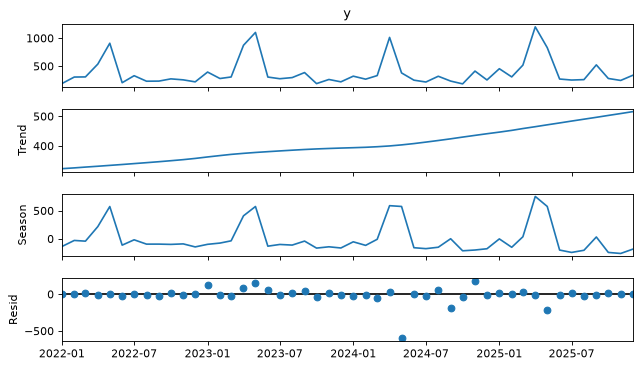

In [7]:
from statsmodels.tsa.seasonal import STL

g = v[v["category"] == "Leisure"].groupby("unique_id").get_group(v.loc[v["category"] == "Leisure", "unique_id"].iloc[0])
STL(g.set_index("ds")["y"].asfreq("MS"), period=12, robust=True).fit().plot()
plt.gcf().set_size_inches(8, 5)
plt.show()

On the demo, the per-household trees lean on `lag2`, `mean6` and `lag12`. That `lag2` (two
months before) tops several categories is a warning sign rather than an insight: with a dozen
series of 36 months, a tree can split on a lag that happened to fit the training months. SHAP
faithfully explains such a model, it does not make it right; the back-test, which rarely
chooses the trees, is what protects the household.

## What to tell a household

- For an average, the method **is** the explanation; for ETS, its shape in words ("a level and
  a yearly season, updated each month") and the season's peak months; for the trees, the top
  contributions ("mostly the same month last year and the calendar month").
- SHAP explains the **model**, not the world: "the calendar month weighed most" means the model
  leans on seasonality, not that July *causes* spending. Causal questions ("did my target lower
  my spending?") need the methods of notebook 08.